# Entraînement des réseaux profonds, softmax et régularisation

CSI 4506 - automne 2026

Marcel Turcotte  
Version: oct. 17, 2026 16h12

# Préambule

## Message du jour

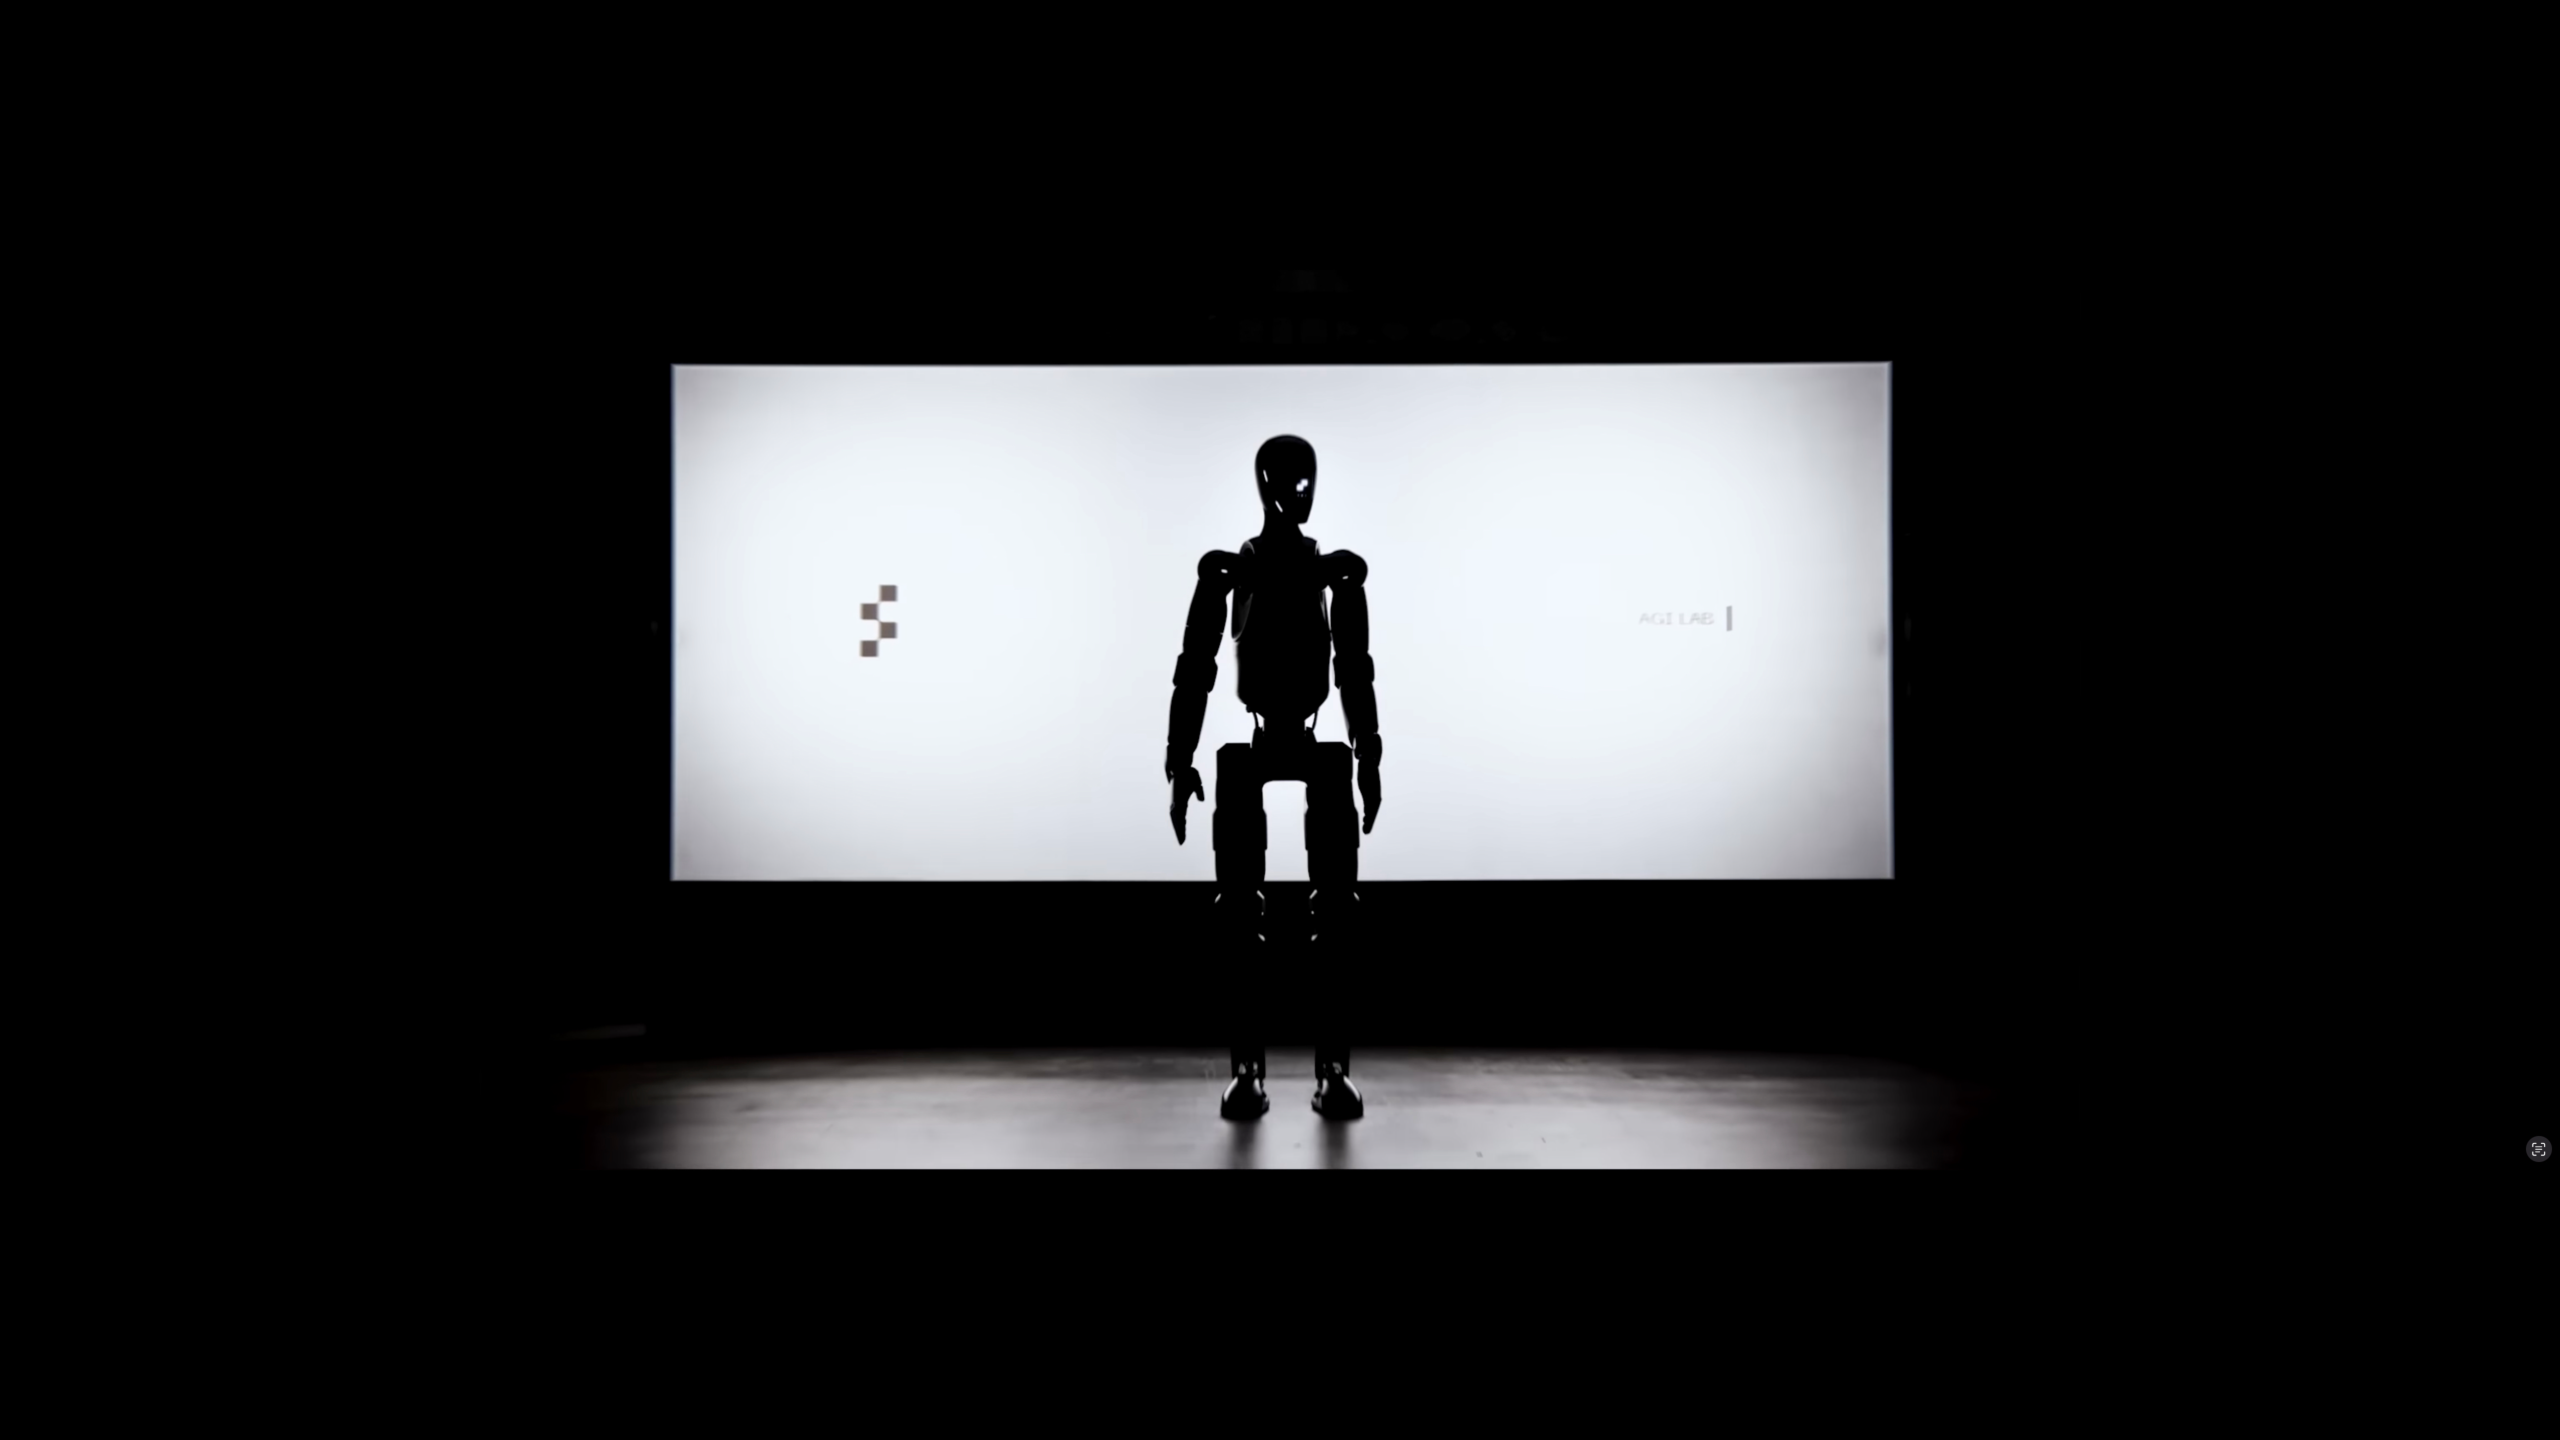

[Why 2025 is the single most pivotal year in our
lifetime](https://bigthink.com/series/the-big-think-interview/great-inflection-2025/),
Peter Leyden, Big Think,
[YouTube](https://www.youtube.com/watch?v=w5k72A30kUc), 2025-10-20.

## Objectifs d’apprentissage

- **Expliquer** comment les fonctions d’activation et l’initialisation
  influencent la propagation des gradients.

- **Comparer** `SimplerMLP` à son extension offrant un choix
  d’activations, la régularisation L2 et la décroissance du taux
  d’apprentissage.

- **Expliquer** le rôle de softmax et de l’entropie croisée dans la
  mesure de la dissimilarité entre les distributions de probabilités
  prédites et réelles.

- **Explorer** la régularisation L1, L2 et le dropout pour améliorer la
  généralisation des réseaux de neurones.

La présentation 13 a implémenté la rétropropagation dans `SimplerMLP`,
avec des unités sigmoïdes, l’entropie croisée binaire et un taux
d’apprentissage constant. Nous examinons d’abord la propagation des
gradients et l’initialisation, puis nous étendons cette implémentation
sous le nom `SimpleMLP`. Les sections suivantes portent sur les
activations de sortie, l’entropie croisée multiclasse et la
régularisation.

# Propagation des gradients et initialisation

## Gradients évanescents

- La rétropropagation multiplie de façon répétée des **poids et des
  dérivées locales d’activation**.
- De petits facteurs peuvent rendre les gradients des premières couches
  trop faibles pour un apprentissage efficace.
- Les unités sigmoïdes saturées ont des dérivées proches de zéro.

Rappel : $\sigma'(z)=\sigma(z)(1-\sigma(z))\leq 0.25$.

L’exemple scalaire de la présentation 13 comportait une seule dérivée
d’activation cachée. Un réseau plus profond introduit davantage de ces
facteurs le long de chaque chemin. La dérivée de la sigmoïde tend vers
zéro lorsque les préactivations prennent de grandes valeurs positives ou
négatives. Les unités saturées peuvent donc atténuer fortement le signal
propagé vers l’amont.

Les poids interviennent aussi dans ces produits, et les différents
chemins contribuent par des sommes. La borne de $0.25$ sur la dérivée
locale de la sigmoïde n’est donc pas une borne sur tous les gradients
complets des paramètres. Les gradients peuvent diminuer ou augmenter
selon l’effet combiné des transformations. Les gradients évanescents
(*vanishing gradients*) et les gradients explosifs (*exploding
gradients*) peuvent apparaître dans les réseaux à propagation avant
comme dans les réseaux récurrents.

Pour une sortie sigmoïde avec entropie croisée binaire, le signal
d’erreur de sortie se simplifie en $\hat p-y$. Le facteur sigmoïde
explicite s’annule à cet endroit, mais les unités sigmoïdes cachées
introduisent toujours leurs dérivées d’activation. La formule simplifiée
de sortie ne supprime donc pas le problème des couches cachées.

## Fonctions d’activation et leurs dérivées

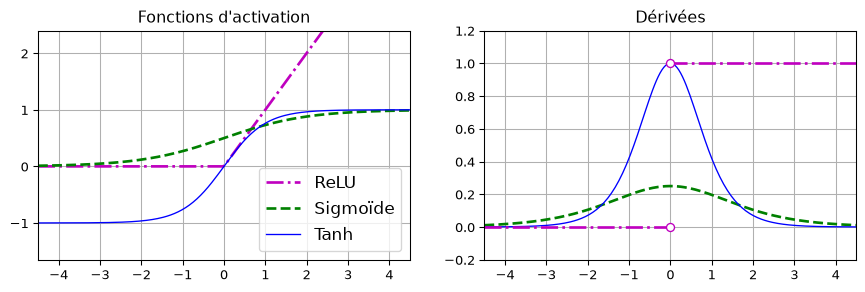

In [2]:
# Attribution : https://github.com/ageron/handson-ml3/blob/main/10_neural_nets_with_keras.ipynb

import numpy as np
import matplotlib.pyplot as plt

from scipy.special import expit as sigmoid

def relu(z):
    return np.maximum(0, z)

def derivative(f, z, eps=0.000001):
    return (f(z + eps) - f(z - eps))/(2 * eps)

max_z = 4.5
z = np.linspace(-max_z, max_z, 200)

plt.figure(figsize=(11, 3.1))

plt.subplot(121)
plt.plot(z, relu(z), "m-.", linewidth=2, label="ReLU")
plt.plot(z, sigmoid(z), "g--", linewidth=2, label="Sigmoïde")
plt.plot(z, np.tanh(z), "b-", linewidth=1, label="Tanh")
plt.grid(True)
plt.title("Fonctions d'activation")
plt.axis([-max_z, max_z, -1.65, 2.4])
plt.gca().set_yticks([-1, 0, 1, 2])
plt.legend(loc="lower right", fontsize=13)

plt.subplot(122)
plt.plot(z, derivative(sigmoid, z), "g--", linewidth=2, label="Sigmoïde")
plt.plot(z, derivative(np.tanh, z), "b-", linewidth=1, label="Tanh")
plt.plot([-max_z, 0], [0, 0], "m-.", linewidth=2)
plt.plot([0, max_z], [1, 1], "m-.", linewidth=2)
plt.plot([0, 0], [0, 1], "mo", markersize=6, markerfacecolor="white")
plt.grid(True)
plt.title("Dérivées")
plt.axis([-max_z, max_z, -0.2, 1.2])

plt.show()

Géron (2022) – <a
href="https://github.com/ageron/handson-ml3/blob/main/10_neural_nets_with_keras.ipynb"
class="external" data-icon="true">10_neural_nets_with_keras.ipynb</a>

Le choix de l’activation influence la propagation des gradients et donc
l’entraînement. Il faut interpréter ces pentes et comprendre leur rôle
dans la règle de la chaîne, plutôt que calculer manuellement chaque
expression.

La dérivée maximale de la sigmoïde est $0.25$ et sa dérivée tend vers
zéro aux deux extrêmes. La dérivée de $\tanh$ atteint un à zéro et tend
aussi vers zéro dans ses régions saturées.

Pour ReLU, la dérivée vaut zéro lorsque la préactivation est négative et
un lorsqu’elle est positive. À zéro, la dérivée ordinaire n’est pas
définie. Les implémentations choisissent une valeur par convention,
généralement zéro. Les cercles ouverts indiquent cette absence de
dérivée ordinaire. L’activation elle-même peut prendre toute valeur non
négative : c’est sa dérivée, hors de zéro, qui ne prend que les valeurs
zéro et un.

ReLU produit des activations éparses, car sa sortie est nulle pour les
entrées non positives. Une activation nulle pour un exemple est normale.
Une unité qui reste dans cette région pour les entrées d’entraînement
considérées ne reçoit aucun gradient de la perte des données à travers
son activation et peut rester inactive : c’est le problème des neurones
ReLU inactifs (*dying ReLU*). Il s’agit d’une inactivité persistante,
pas simplement d’une sortie nulle. Des modifications des représentations
en amont peuvent parfois réactiver une unité. L’inactivité n’est donc
pas toujours irréversible. Voir
<a href="https://arxiv.org/abs/1903.06733" class="external"
data-icon="true">Lu et al. (2019)</a>.

La dérivée de ReLU du côté positif évite une source d’atténuation, mais
ne rend pas le gradient complet égal à un. Les activations entrantes,
les poids en aval, les autres dérivées d’activation et les sommes de
chemins interviennent toujours. Leaky ReLU conserve une petite pente du
côté négatif, ce qui réduit ce risque particulier.

## Gradients évanescents : solutions

- **Autres fonctions d’activation** : unité linéaire rectifiée
  (**ReLU**) et ses variantes, comme **Leaky ReLU**, **Parametric ReLU**
  et **Exponential Linear Unit**.

- **Initialisation des poids** : initialisation Xavier (Glorot) ou He.

Les fonctions d’activation et l’initialisation influencent la
propagation des signaux dans les deux sens. ReLU évite la saturation
pour les préactivations positives, mais sa dérivée nulle du côté négatif
crée une autre limite, examinée ensuite. Choisir ReLU ne garantit pas la
stabilité des gradients dans un réseau arbitrairement profond. Les
couches de normalisation et les connexions résiduelles offrent d’autres
approches, au-delà de cette implémentation.

## Glorot et Bengio

Figure 6

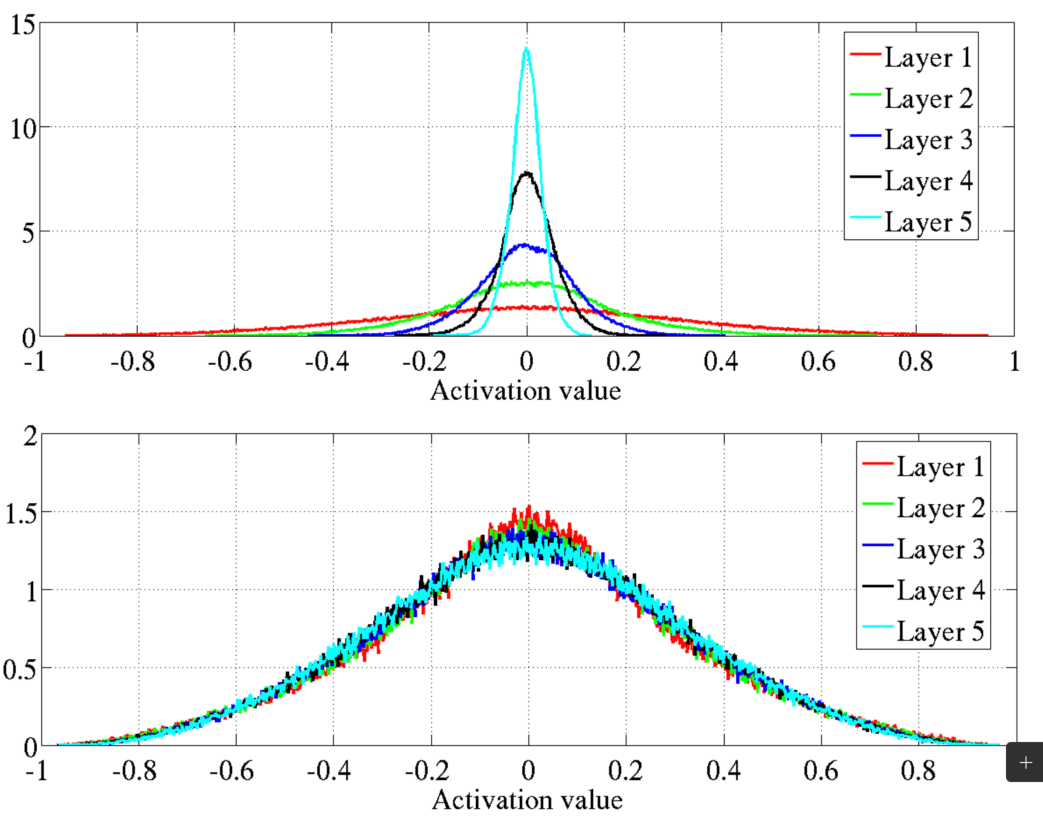

Figure 7

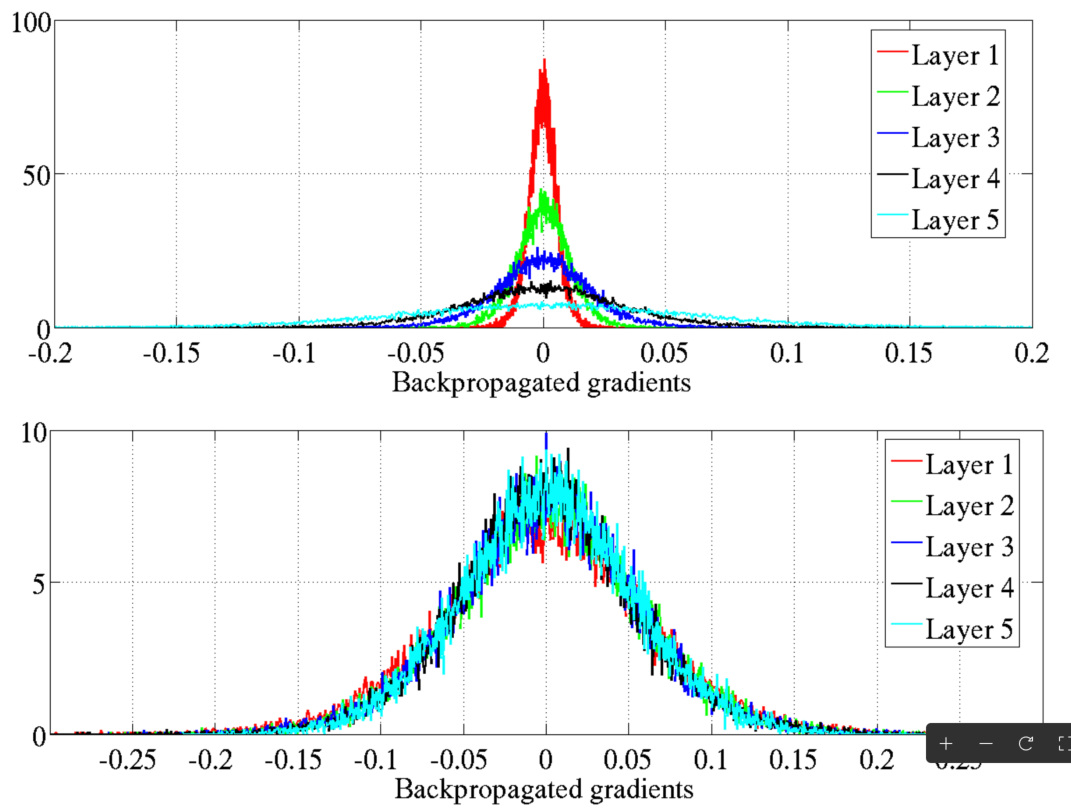

Glorot et Bengio (2010), page 254.

Ces figures comparent l’initialisation standard, en haut, à
l’initialisation normalisée proposée par Glorot et Bengio, en bas, pour
un réseau à unités $\tanh$ (Glorot et Bengio 2010, 254). La figure 6
montre les histogrammes des activations, et la figure 7 ceux des
gradients rétropropagés. Avec l’initialisation standard, les activations
se concentrent davantage près de zéro dans les couches ultérieures,
tandis que les gradients rétropropagés se concentrent davantage près de
zéro à proximité de l’entrée. L’initialisation normalisée réduit les
écarts entre les couches dans ces expériences.

Ces distributions correspondent au cadre expérimental rapporté. Elles
n’établissent pas une règle universelle selon laquelle les gradients
évanescents impliquent toujours de petites activations avant. Une
sigmoïde saturée peut avoir une activation proche de un et une dérivée
proche de zéro. L’article distingue aussi les signaux rétropropagés des
gradients des poids. Leurs distributions par couche ne se comportent pas
nécessairement de la même façon.

L’initialisation normale Xavier/Glorot équilibre les largeurs d’entrée
et de sortie par
$\operatorname{Var}(W)=2/(n_{\mathrm{in}}+n_{\mathrm{out}})$. Il s’agit
de l’initialisation aléatoire avec mise à l’échelle déjà utilisée par
`SimplerMLP`.

## Initialisation He

Pour les couches cachées ReLU, l’initialisation normale He utilise

$$
\operatorname{Var}(W)=\frac{2}{n_{\mathrm{in}}}.
$$

``` python
def he_init(rng, fan_in, fan_out):
    std = np.sqrt(2.0 / fan_in)
    return rng.normal(0.0, std, size=(fan_in, fan_out))
```

Aussi appelée initialisation Kaiming.

La mise à l’échelle tient compte de l’effet de la rectification sur la
variance des signaux. `SimpleMLP` utilisera l’initialisation He pour les
couches cachées ReLU et Xavier/Glorot pour les couches sigmoïdes, y
compris la sortie. Ces règles d’initialisation ne garantissent pas le
comportement de toute la trajectoire d’entraînement. Voir
<a href="https://arxiv.org/abs/1502.01852" class="external"
data-icon="true">He et al. (2015)</a> pour l’analyse des unités
rectifiées.

## Remarque

L’initialisation aléatoire des poids[1] suffit à **briser la symétrie**
d’un réseau de neurones. Les **biais peuvent donc commencer à zéro**
sans empêcher les unités d’apprendre des caractéristiques distinctes.

## Fonction d’activation : Leaky ReLU

[1] L’initialisation des poids, par exemple Xavier/Glorot ou He, doit
être adaptée à la fonction d’activation pour favoriser un apprentissage
efficace.

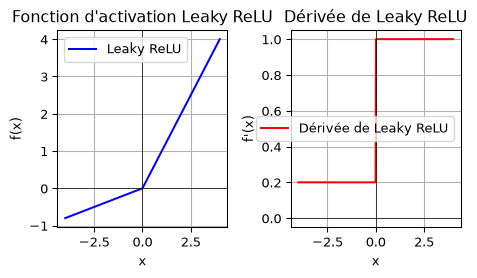

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Définir la fonction Leaky ReLU
def leaky_relu(x, alpha=0.2):
    return np.where(x > 0, x, alpha * x)

# Définir la dérivée de Leaky ReLU
def leaky_relu_derivative(x, alpha=0.2):
    return np.where(x > 0, 1, alpha)

# Générer une plage de valeurs d'entrée
x_values = np.linspace(-4, 4, 400)

# Calculer Leaky ReLU et sa dérivée
leaky_relu_values = leaky_relu(x_values)
leaky_relu_derivative_values = leaky_relu_derivative(x_values)

# Créer le graphique
plt.figure(figsize=(5, 3))

# Tracer Leaky ReLU
plt.subplot(1, 2, 1)
plt.plot(x_values, leaky_relu_values, label='Leaky ReLU', color='blue')
plt.title("Fonction d'activation Leaky ReLU")
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid(True)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)
plt.legend()

# Tracer la dérivée de Leaky ReLU
plt.subplot(1, 2, 2)
plt.plot(x_values, leaky_relu_derivative_values, label='Dérivée de Leaky ReLU', color='red')
plt.title('Dérivée de Leaky ReLU')
plt.xlabel('x')
plt.ylabel("f'(x)")
plt.grid(True)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)
plt.legend()

# Afficher les graphiques
plt.tight_layout()
plt.show()

Leaky ReLU, une variante de ReLU, atténue le problème des neurones ReLU
qui restent inactifs. Pour les entrées négatives, elle introduit une
composante linéaire dont la pente est contrôlée par le paramètre
`negative_slope`.

Lorsque l’entrée de ReLU, soit la somme pondérée plus le biais, est
négative pour tous les exemples d’entraînement, sa sortie est nulle. Sa
dérivée est aussi nulle, ce qui désactive le neurone. Leaky ReLU et
d’autres variantes atténuent ce problème.

``` python
import tensorflow as tf
from tensorflow.keras.layers import Dense

leaky_relu = tf.keras.layers.LeakyReLU(negative_slope=0.2)
dense = tf.keras.layers.Dense(50, activation=leaky_relu, kernel_initializer="he_normal")
```

Consultez les
<a href="https://keras.io/api/layers/activations/" class="external"
data-icon="true">fonctions d’activation Keras</a> pour d’autres choix.

# Extension de l’implémentation

## De SimplerMLP à SimpleMLP

| Composante | `SimplerMLP` (présentation 13) | `SimpleMLP` |
|:-----------------------|:-----------------------|:-----------------------|
| Activation cachée | Sigmoïde | Sigmoïde ou ReLU |
| Sortie | Probabilité sigmoïde | Probabilité sigmoïde |
| Taux d’apprentissage | Constant | Constant ou décroissance exponentielle |
| Perte | BCE moyenne | BCE moyenne et pénalité L2 optionnelle |
| Ordre des exemples | Mélange à chaque époque | Mélange optionnel, activé par défaut |
| Valeurs conservées et boucle arrière | Même structure | Même structure |
| API de prédiction et d’entraînement | Mêmes méthodes | Mêmes méthodes |

La nouvelle classe étend l’implémentation précédente en conservant sa
structure de calcul. Les deux sont des classificateurs binaires avec une
sortie sigmoïde. Changer l’activation cachée exige une dérivée locale
correspondante et une initialisation appropriée, mais la règle de la
chaîne et la boucle arrière restent les mêmes.

Les réglages `hidden_activation="sigmoid"`, `l2=0.0` et `lr_decay=None`
retrouvent le calcul de `SimplerMLP`. Avec la même graine et la valeur
par défaut `shuffle=True`, les deux classes effectuent la même
initialisation et le même mélange. `SimpleMLP` ajoute une option
`shuffle` à `train` : `shuffle=False` conserve l’ordre fourni des
exemples d’une époque à l’autre. Cette option est utile lorsque
l’entraînement dépend de cet ordre, comme discuté dans la présentation
13. Elle ne transforme pas à elle seule ce classificateur à propagation
avant en modèle séquentiel. La définition complète ci-dessous permet une
exécution autonome du carnet. Les extraits suivants mettent l’accent sur
les ajouts.

## SimpleMLP

In [4]:
import numpy as np

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_prime(z):
    a = sigmoid(z)
    return a * (1.0 - a)

def bce_loss(y_true, y_prob, eps=1e-9):
    """Entropie croisée binaire moyennée sur les exemples."""
    p = np.clip(y_prob, eps, 1 - eps)
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def xavier_init(rng, fan_in, fan_out):
    std = np.sqrt(2.0 / (fan_in + fan_out))
    return rng.normal(0.0, std, size=(fan_in, fan_out))

def relu(z):
    return np.maximum(0.0, z)

def relu_prime(z):
    return (z > 0).astype(float)

def he_init(rng, fan_in, fan_out):
    std = np.sqrt(2.0 / fan_in)
    return rng.normal(0.0, std, size=(fan_in, fan_out))

class SimpleMLP:
    """MLP binaire avec options ReLU, L2 et décroissance du taux."""

    def __init__(self, layer_sizes, lr=0.1, seed=None, l2=0.0,
                 hidden_activation="relu", lr_decay=None):
        self.sizes = list(layer_sizes)
        self.lr = float(lr)
        self.base_lr = float(lr)
        self.l2 = float(l2)
        self.hidden_activation = hidden_activation
        self.lr_decay = lr_decay
        self.rng = np.random.default_rng(seed)

        self.W = []
        L = len(self.sizes) - 1
        for l, (din, dout) in enumerate(zip(self.sizes[:-1], self.sizes[1:]), start=1):
            if l < L and self.hidden_activation == "relu":
                Wk = he_init(self.rng, din, dout)
            else:
                Wk = xavier_init(self.rng, din, dout)
            self.W.append(Wk)
        self.b = [np.zeros(dout) for dout in self.sizes[1:]]

    def _act(self, z, last=False):
        if last:
            return sigmoid(z)
        return relu(z) if self.hidden_activation == "relu" else sigmoid(z)

    def _act_prime(self, z, last=False):
        if last:
            return sigmoid_prime(z)
        return relu_prime(z) if self.hidden_activation == "relu" else sigmoid_prime(z)

    def forward(self, X):
        a = X
        L = len(self.W)
        for l, (W, b) in enumerate(zip(self.W, self.b), start=1):
            a = self._act(a @ W + b, last=(l == L))
        return a.ravel()

    def predict_proba(self, X):
        return self.forward(X)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def loss(self, X, y):
        p = self.predict_proba(X)
        base = bce_loss(y, p)
        if self.l2 > 0:
            base += 0.5 * self.l2 * sum((W ** 2).sum() for W in self.W)
        return base

    def _forward_full(self, X):
        a = X
        activations = [a]
        zs = []
        L = len(self.W)
        for l, (W, b) in enumerate(zip(self.W, self.b), start=1):
            z = a @ W + b
            a = self._act(z, last=(l == L))
            zs.append(z)
            activations.append(a)
        return activations, zs

    def train(self, X, y, epochs=30, batch_size=None, verbose=True, shuffle=True):
        """X : (N, d), y : (N,); batch_size=None utilise tout le jeu de données."""
        N = X.shape[0]
        idx = np.arange(N)
        B = N if batch_size is None else int(batch_size)

        for ep in range(1, epochs + 1):
            if shuffle:
                self.rng.shuffle(idx)
            if self.lr_decay is not None:
                self.lr = self.base_lr * self.lr_decay ** (ep - 1)

            base_loss = self.loss(X, y)

            for start in range(0, N, B):
                sl = idx[start:start + B]
                Xb = X[sl]
                yb = y[sl].reshape(-1, 1)
                Bsz = Xb.shape[0]

                activations, zs = self._forward_full(Xb)
                A_L = activations[-1]

                # Chaque ligne est la sensibilité aux préactivations d'un exemple.
                delta = A_L - yb
                grads_W = [None] * len(self.W)
                grads_b = [None] * len(self.b)

                # Calculer une seule fois la moyenne des gradients sur les exemples.
                grads_W[-1] = activations[-2].T @ delta / Bsz
                grads_b[-1] = delta.mean(axis=0)

                for k in range(len(self.W) - 2, -1, -1):
                    z = zs[k]
                    d_act = self._act_prime(z, last=False)
                    delta = (delta @ self.W[k + 1].T) * d_act
                    grads_W[k] = activations[k].T @ delta / Bsz
                    grads_b[k] = delta.mean(axis=0)

                if self.l2 > 0:
                    for k in range(len(self.W)):
                        grads_W[k] += self.l2 * self.W[k]

                # Tous les gradients utilisent les poids du même passage avant.
                for k in range(len(self.W)):
                    self.W[k] -= self.lr * grads_W[k]
                    self.b[k] -= self.lr * grads_b[k]

            new_loss = self.loss(X, y)
            if verbose:
                print(f"Époque {ep:3d} | perte {base_loss:.5f} -> {new_loss:.5f} | lr={self.lr:.4f}")

## Choix des activations cachées

``` python
    def _act(self, z, last=False):
        if last:
            return sigmoid(z)
        return relu(z) if self.hidden_activation == "relu" else sigmoid(z)

    def _act_prime(self, z, last=False):
        if last:
            return sigmoid_prime(z)
        return relu_prime(z) if self.hidden_activation == "relu" else sigmoid_prime(z)
```

La sortie reste sigmoïde pour la classification binaire. L’option ReLU
concerne uniquement les unités cachées. La présentation 13 appelait
directement `sigmoid` et `sigmoid_prime`. Ici, les méthodes `_act` et
`_act_prime` sélectionnent l’activation et sa dérivée. L’indicateur
`last` identifie la couche de sortie. Les méthodes de passage avant,
avec ou sans conservation des valeurs, appellent maintenant `_act`. La
boucle arrière appelle `_act_prime`. La multiplication par `W_next.T` et
la moyenne sur les exemples restent inchangées.

## Décroissance du taux d’apprentissage

À l’époque $t=1,2,\ldots$, avec un facteur de décroissance $0<\gamma<1$
:

$$
\alpha_t=\alpha_1\gamma^{t-1}.
$$

``` python
if self.lr_decay is not None:
    self.lr = self.base_lr * self.lr_decay ** (ep - 1)
```

La première époque utilise le taux d’apprentissage initial. Les époques
suivantes utilisent des pas progressivement plus petits. Avec
`lr_decay=None`, le taux reste constant. La décroissance modifie la
taille du pas de l’optimiseur, pas les formules des dérivées ni
l’objectif. Elle diffère de la régularisation L2 et de la décroissance
des poids (*weight decay*). Réduire le taux trop rapidement peut
empêcher des progrès utiles. Cela ne corrige pas les gradients
évanescents.

## L2 dans l’objectif et le gradient

$$
J_{\mathrm{reg}}=J_{\mathrm{BCE}}+
\frac{\lambda}{2}\sum_{l=1}^{L}\|W^{(l)}\|_F^2.
$$

``` python
base += 0.5 * self.l2 * sum((W ** 2).sum() for W in self.W)

# Après le calcul des gradients moyens de la perte des données :
grads_W[k] += self.l2 * self.W[k]
```

Le coefficient `l2` correspond à $\lambda$. La perte des données est
moyennée sur les exemples. La pénalité est ajoutée séparément, sans
division supplémentaire par la taille du jeu de données ou du mini-lot.
Sa dérivée est donc $\lambda W$ dans chaque lot. L’objectif rapporté et
le gradient de mise à jour restent ainsi cohérents. Les biais ne sont
pas pénalisés dans cette implémentation.

Le carré de la norme de Frobenius est simplement la somme des carrés des
éléments d’une matrice de poids. L2 décourage les grands poids, mais ne
change pas les dérivées locales d’activation et ne corrige pas
directement la propagation des gradients. La section ultérieure sur la
régularisation développera la motivation liée à la généralisation et les
autres méthodes.

## Même API, modèle étendu

In [5]:
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

X, y = make_circles(n_samples=200, factor=0.5, noise=0.08, random_state=1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = SimpleMLP([2, 4, 4, 1], lr=0.3, seed=42,
                  hidden_activation="relu", l2=0.001, lr_decay=0.995)
model.train(X_train, y_train, epochs=500, batch_size=32, verbose=False)

print("Exactitude (entraînement) :", accuracy_score(y_train, model.predict(X_train)))
print("Exactitude (test) :", accuracy_score(y_test, model.predict(X_test)))

Exactitude (entraînement) : 1.0
Exactitude (test) : 1.0

Cet exemple utilise les mêmes données, séparation, prétraitement et
architecture que l’exemple `SimplerMLP`. Il montre comment activer les
options supplémentaires. Comme l’activation, la durée d’entraînement, la
pénalité et le calendrier du taux d’apprentissage diffèrent, ces deux
exécutions illustrent des processus complets plutôt qu’une comparaison
contrôlée qui établirait la supériorité universelle d’un réglage. Les
graines des deux constructeurs contrôlent les poids et le mélange. Tous
les gradients sont toujours calculés avant les mises à jour.

# Couche de sortie

## Couche de sortie : tâche de régression

- **\# de neurones de sortie** :
  - 1 par dimension
- **Fonction d’activation de la couche de sortie** :
  - Aucune, *ReLU/softplus* si positif, *sigmoid/tanh* si borné
- **Fonction de perte** :
  - [MeanSquaredError](https://www.tensorflow.org/api_docs/python/tf/keras/losses/MeanSquaredError)

Dans un [problème de détection
d’objet](https://keras.io/guides/keras_cv/object_detection_keras_cv/),
la détermination de la **boîte englobante** est un exemple de tâche de
régression où la sortie est multidimensionnelle.

Commen choisit-on les fonctions d’activation?

Dans un réseau feed-forward, les fonctions d’activation dans les couches
cachées sont choisies principalement pour leur impact sur la performance
et la convergence, tandis que la fonction d’activation dans la couche de
sortie est sélectionnée selon les exigences de la tâche.

- **Couches cachées :**

  La fonction d’activation (par exemple, ReLU, GELU, tanh) affecte
  principalement la *dynamique de l’entraînement*; comme le flux de
  gradient, la force de non-linéarité et le taux de convergence. Le
  choix est généralement empirique, guidé par la performance, la
  stabilité numérique et le comportement d’optimisation.

- **Couche de sortie :**

  La fonction d’activation est déterminée par la **nature de la tâche de
  prédiction** :

  - *Régression* : linéaire, ReLU, ou softplus (selon les contraintes de
    plage)
  - *Classification binaire* : sigmoïde
  - *Classification multi-classes* : softmax
  - *Classification multi-étiquettes* : sigmoïde (par unité de sortie)

Exemples de **problèmes de régression à sorties multiples** (2–4
sorties) incluent :

- **2 sorties :**

  - Prédire à la fois la **latitude et la longitude** d’un emplacement à
    partir d’une image.
  - Estimer la **largeur et la hauteur** d’une boîte englobante en
    détection d’objets.
  - Prévoir simultanément la **température et l’humidité**.

- **3 sorties :**

  - Prédire les **coordonnées x, y, z** d’un point dans l’espace (par
    exemple, localisation d’une articulation de main).
  - Estimer les **valeurs de couleur RGB** à partir de mesures
    spectrales.

- **4 sorties :**

  - Prédire les **coordonnées de la boîte englobante** —
    $(x_{min}, y_{min}, x_{max}, y_{max})$ — en détection d’objets.

## Couche de sortie : Multi-étiquette

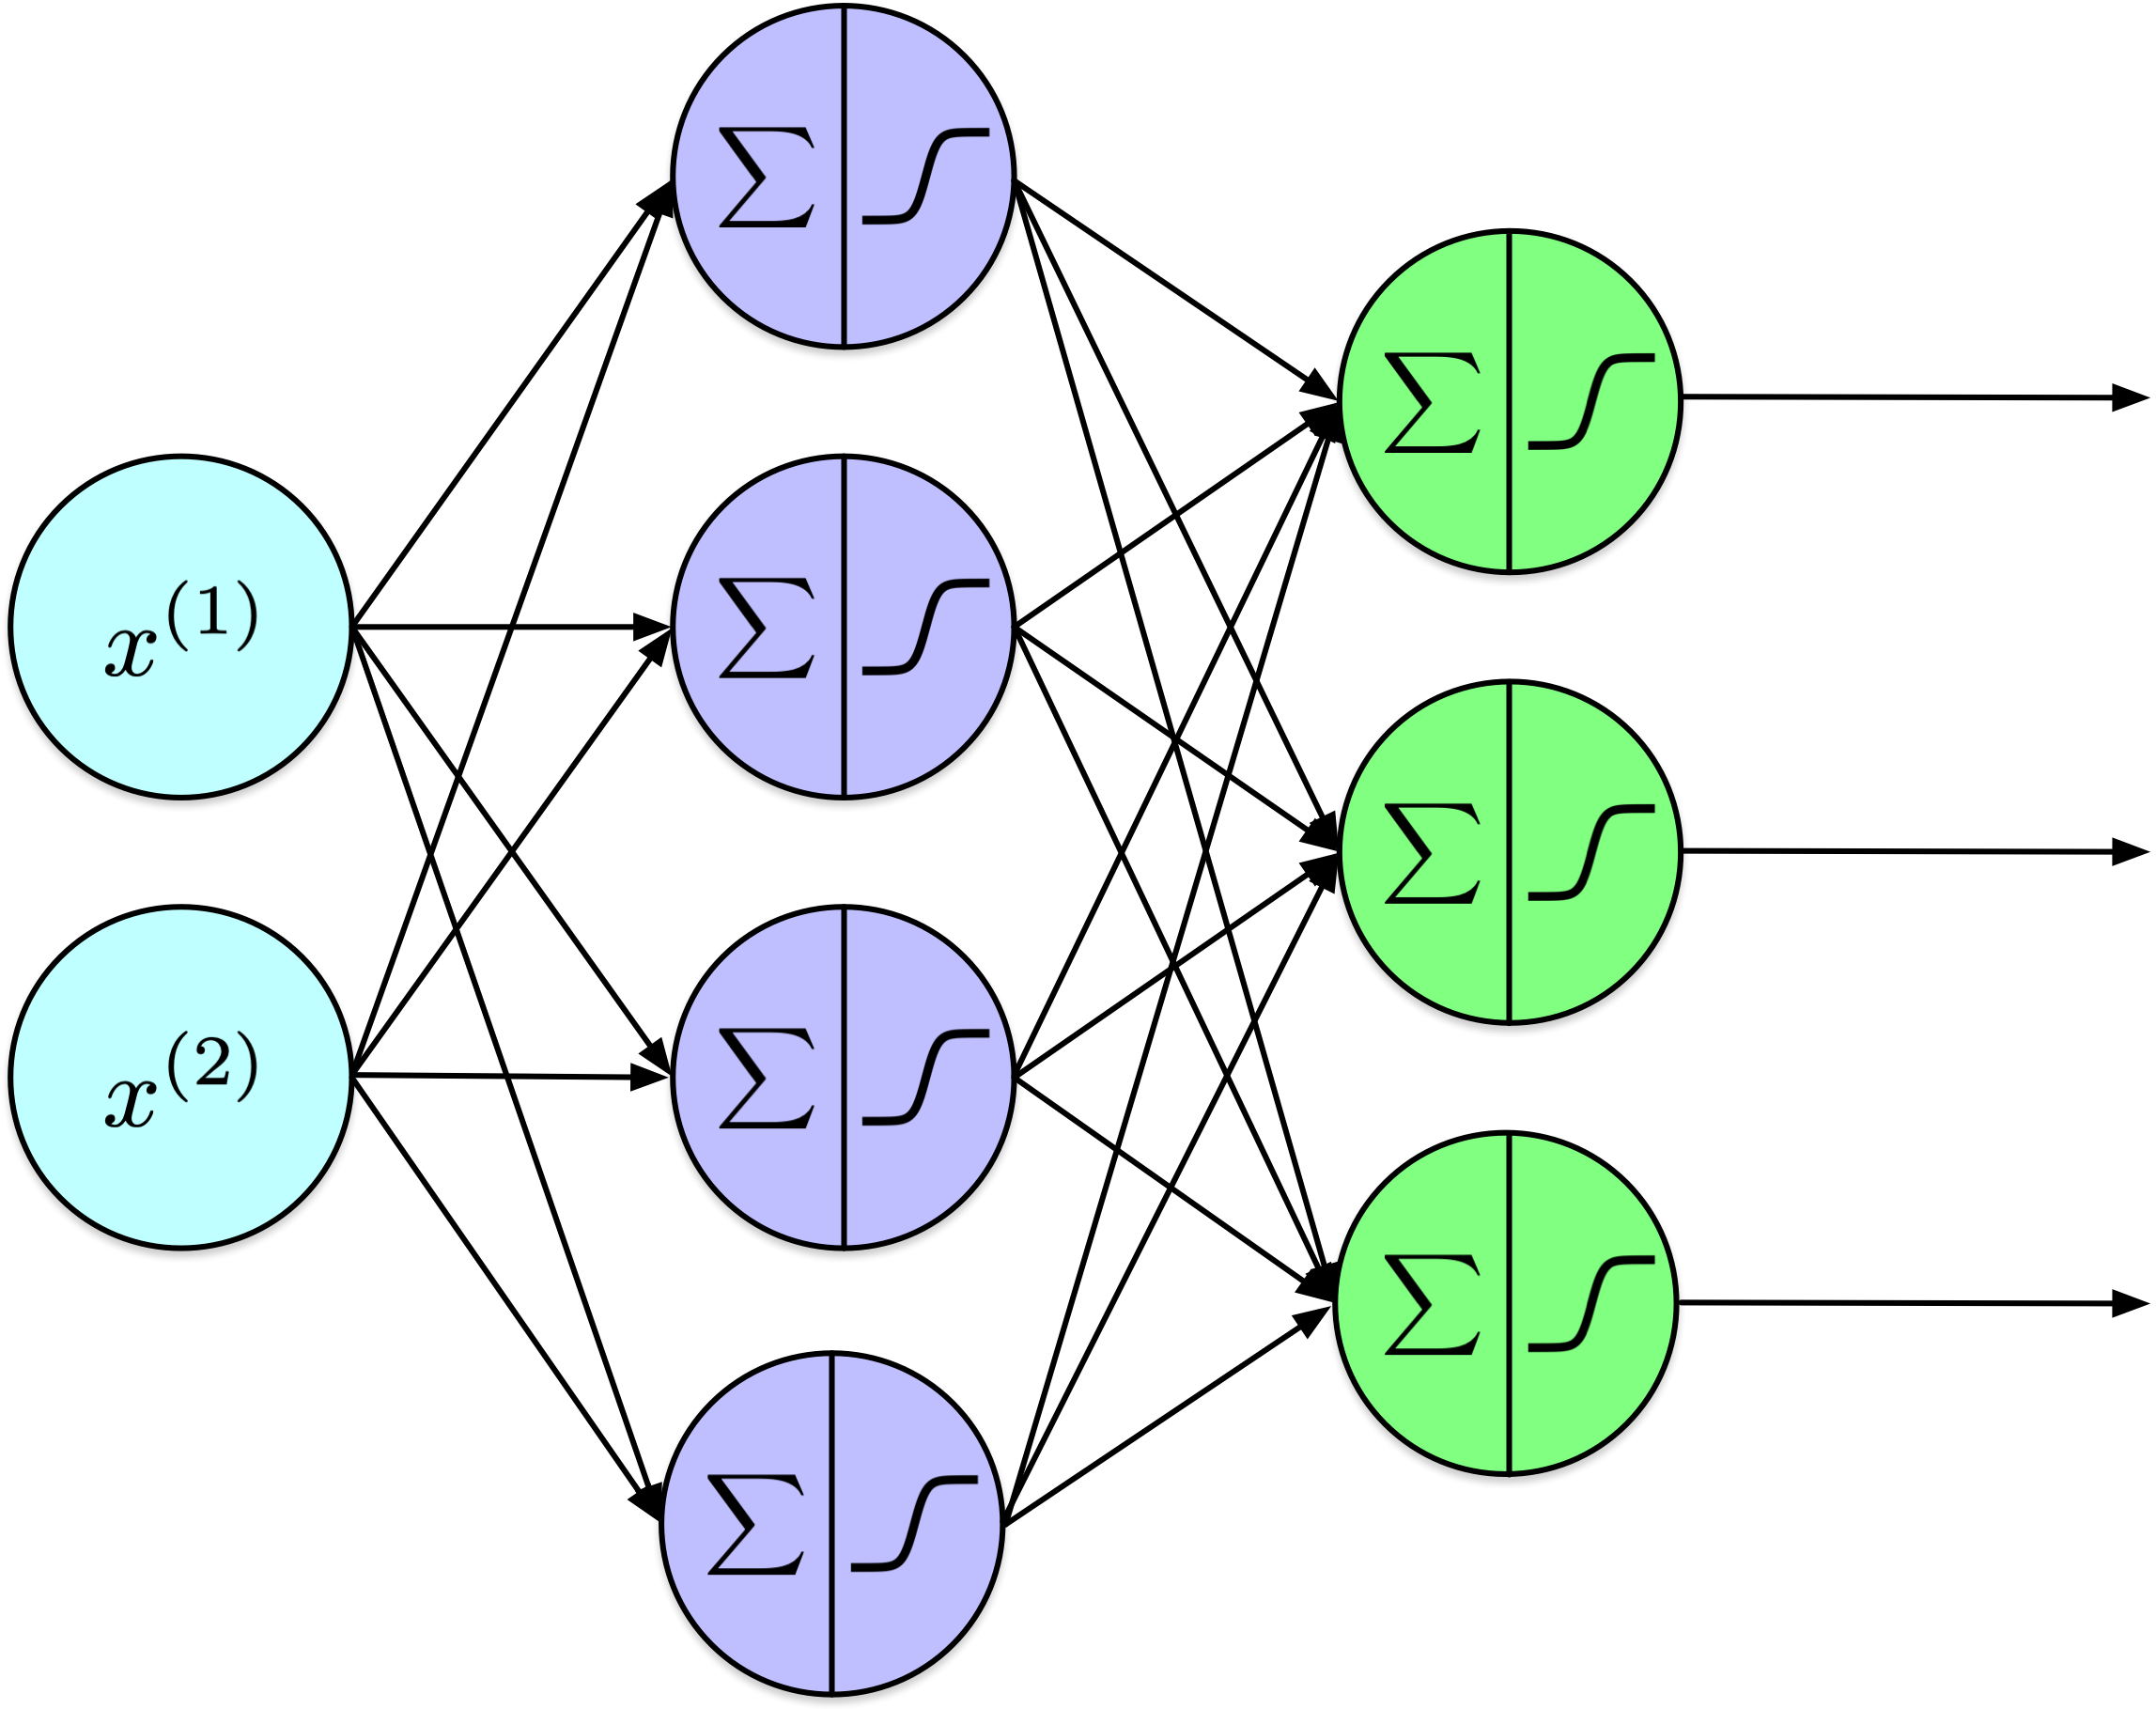

Avec la fonction d’activation sigmoïde, ce réseau effectue des
prédictions multi-étiquettes.

Cependant, ce réseau n’est pas adapté à la classification. Voyez-vous
pourquoi ?

## Couche de sortie : tâche de classification

- **\# de neurones de sortie** :
  - 1 si binaire, 1 par classe si multiclasse ou multilabel.
- **Fonction d’activation de la couche de sortie** :
  - *sigmoid* si binaire ou multilabel, *softmax* si multiclasses.
- **Fonction de perte** :
  - entropie croisée

## Softmax

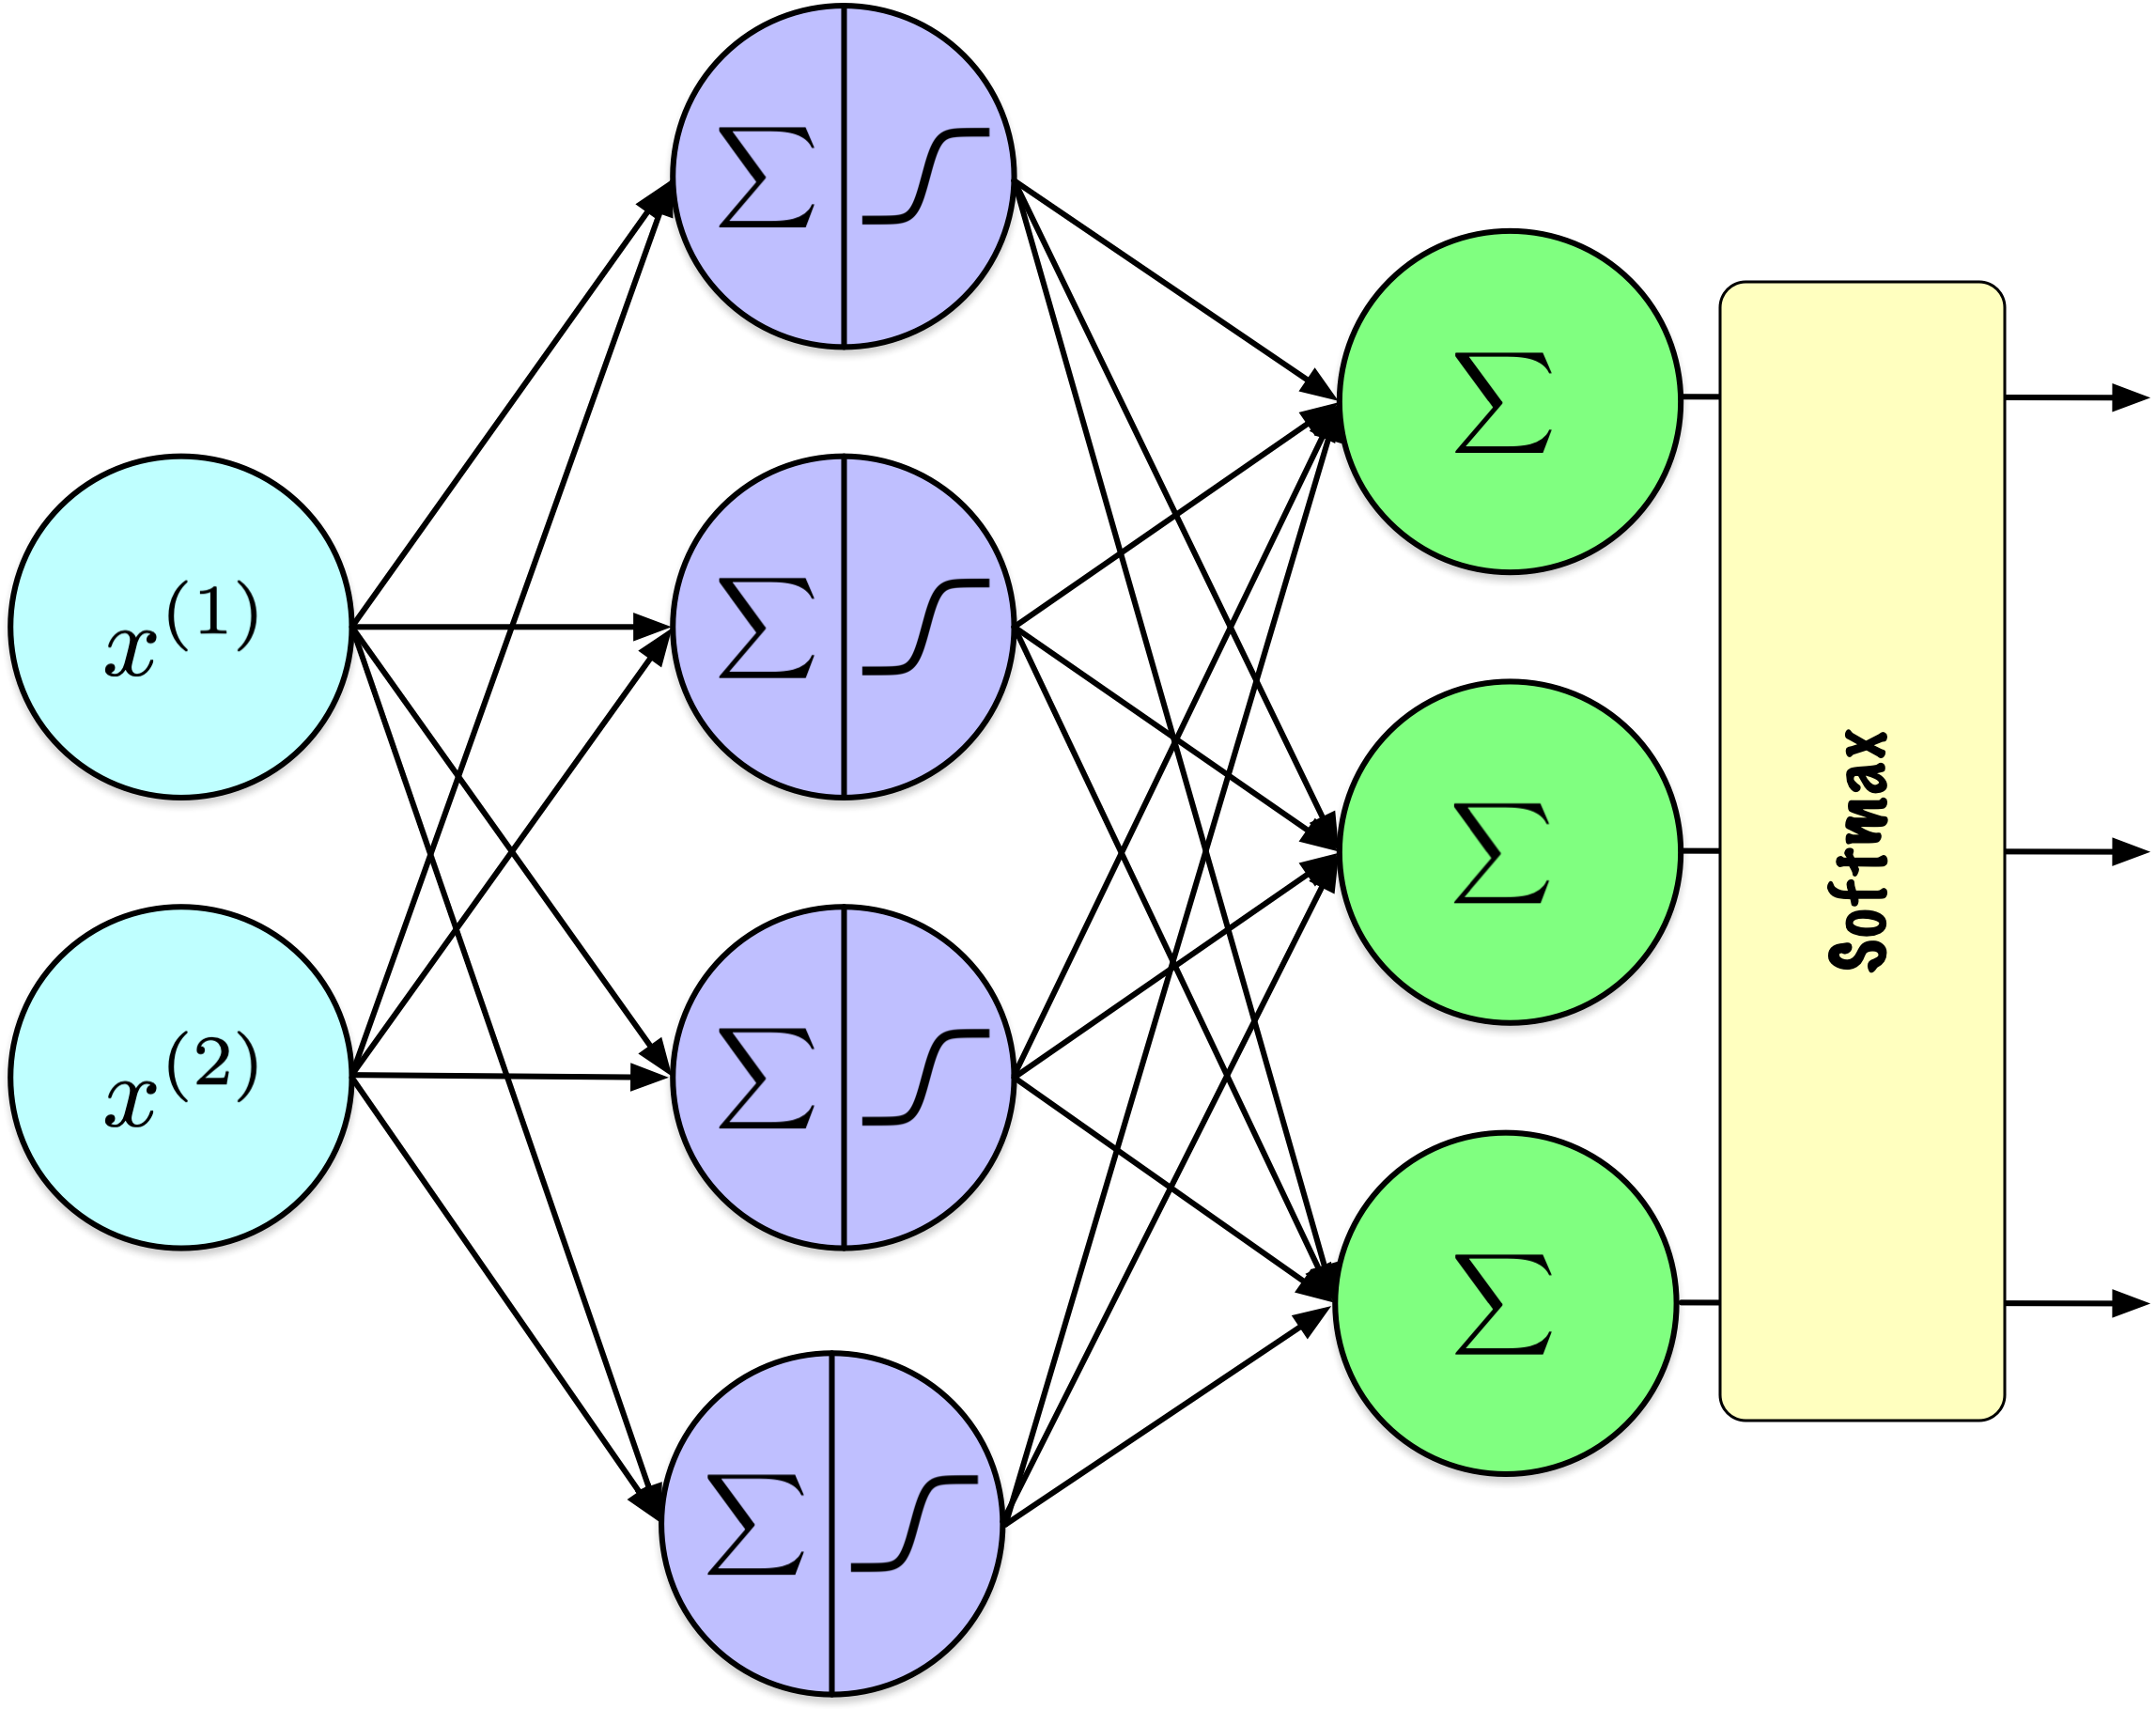

**Softmax** garantit que toutes les sorties d’activation se situent
entre 0 et 1 et que leur somme est égale à 1.

Remarquez que j’ai révisé la représentation des nœuds de sortie pour
indiquer que la fonction softmax est appliquée à l’ensemble de la
couche, plutôt qu’à des nœuds individuels. Cette fonction transforme les
valeurs brutes de sortie de la couche en probabilités qui totalisent 1,
facilitant ainsi la classification multiclasses. Cette caractéristique
la distingue des fonctions d’activation comme ReLU ou sigmoid, qui sont
généralement appliquées indépendamment à la sortie de chaque nœud.

La fonction $\argmax$ n’est pas appropriée pour l’optimisation par des
méthodes basées sur les gradients, car sa dérivée est nulle dans tous
les cas, comme pour les fonctions de seuil. En revanche, la fonction
softmax offre à la fois une interprétation probabiliste et une dérivée
calculable, la rendant plus efficace pour de telles applications.

La fonction $\argmax$ peut être appliquée *a posteriori* aux réseaux
entraînés pour faire des prédictions de classe.

## Softmax

La **fonction softmax** est une **fonction d’activation** utilisée dans
les **problèmes de classification multiclasses** pour convertir un
vecteur de scores bruts en **probabilités qui totalisent 1**.

Étant donné un vecteur $\mathbf{z} = [z_1, z_2, \ldots, z_n]$ :

$$
\sigma(\mathbf{z})_i = \frac{e^{z_i}}{\sum_{j=1}^{n} e^{z_j}}
$$

où $\sigma(\mathbf{z})_i$ est la probabilité de la classe $i$, et $n$
est le nombre de classes.

La fonction softmax met l’accent sur les scores les plus élevés tout en
atténuant les scores les plus faibles, permettant une interprétation
probabiliste des sorties.

On peut clairement voir que cette activation s’applique à l’ensemble de
la couche, puisque la dénomination dépend des valeurs de tous les $z_j$,
pour $j \in 1 \ldots n$.

1.  **Assure la positivité :**

    La fonction exponentielle garantit que toutes les sorties sont
    positives, une propriété nécessaire pour des probabilités valides.

2.  **Amplifie les différences relatives :**

    L’exponentiation est une transformation *non linéaire monotone* qui
    augmente beaucoup plus les grandes valeurs que les petites. Si un
    logit est légèrement plus grand, $e^{z_i}$ devient
    *disproportionnellement plus grand*, accentuant la distribution
    (utile pour mettre en valeur la classe la plus probable).

3.  **Préserve l’ordre :**

    Puisque $e^x$ est strictement croissante, la classe avec le logit le
    plus élevé avant softmax reste celle avec la probabilité la plus
    élevée après.

4.  **Facilite l’apprentissage basé sur le gradient :**

    L’exponentielle adoucit la transition entre les classes, fournissant
    des sorties différentiables et des gradients stables pour
    l’optimisation avec l’entropie croisée.

Un *logit* est une valeur de pré-activation ($z_i$). Chaque neurone dans
la couche de sortie (avant activation) produit un logit $z_i$.

## Softmax

|    $z_1$ |    $z_2$ |    $z_3$ | $\sigma(z_1)$ | $\sigma(z_2)$ | $\sigma(z_3)$ | $\sum$ |
|--------:|--------:|--------:|-------------:|-------------:|-------------:|-------:|
| **1.47** |    -0.39 |     0.22 |      **0.69** |          0.11 |          0.20 |   1.00 |
|     5.00 | **6.00** |     4.00 |          0.24 |      **0.67** |          0.09 |   1.00 |
|     0.90 |     0.80 | **1.10** |          0.32 |          0.29 |      **0.39** |   1.00 |
|    -2.00 | **2.00** |    -3.00 |          0.02 |      **0.98** |          0.01 |   1.00 |

Valeurs de softmax pour un vecteur de longueur 3.

1.  **Maintient l’ordre relatif** : La fonction softmax préserve l’ordre
    relatif des valeurs d’entrée. Si une entrée est supérieure à une
    autre, sa sortie correspondante sera également supérieure.

2.  **Interprétée comme des probabilités** : Chaque valeur se situe dans
    la plage de 0 à 1. Les valeurs de sortie de la fonction softmax sont
    normalisées pour totaliser un, ce qui permet de les interpréter
    comme des probabilités.

3.  **Différences relatives** : Lorsque les différences relatives entre
    les valeurs d’entrée sont petites, les différences dans les
    probabilités de sortie restent petites, reflétant la distribution
    des entrées. Lorsque les valeurs d’entrée sont identiques, les
    sorties seront égales à $\frac{1}{n}$, où $n$ est le nombre de
    classes.

4.  **Large gamme de valeurs** : La fonction softmax peut traiter
    efficacement une large gamme de valeurs d’entrée, grâce à la
    fonction exponentielle et à la normalisation, qui adaptent les
    entrées à une plage probabiliste.

Ces propriétés rendent la fonction softmax particulièrement utile pour
les tâches de classification multiclasses en apprentissage automatique.

## Softmax

<https://www.youtube.com/watch?v=KpKog-L9veg>

## Fonction de perte d’entropie croisée

L’**entropie croisée** dans une **tâche de classification multiclasses**
pour un exemple :

$$
J(W) = -\sum_{k=1}^{K} y_k \log(\hat{y}_k)
$$

Où :

- $K$ est le **nombre de classes**.
- $y_k$ est la **distribution réelle** pour la classe $k$.
- $\hat{y}_k$ est la **probabilité prédite** de la classe $k$ par le
  modèle.

- Le vecteur cible $y$ est exprimé comme un vecteur encodé one-hot de
  longueur $K$, où l’élément correspondant à la classe réelle est fixé à
  1, et tous les autres éléments sont à 0.

- Par conséquent, dans la somme sur les classes, seul le terme associé à
  la classe réelle contribue une valeur non nulle.

- Ainsi, la perte d’entropie croisée pour un exemple unique est donnée
  par $-\log(\hat{y}_k)$, où $\hat{y}_k$ est la probabilité prédite pour
  la classe réelle.

- La probabilité prédite $\hat{y}_k$ est dérivée de la fonction softmax
  appliquée à la couche de sortie du réseau neuronal.

## Fonction de perte d’entropie croisée

- **Problème de classification** : 3 classes
  - Versicolour, Setosa, Virginica.
- **Encodage one-hot** :
  - Setosa = $[0, 1, 0]$.
- **Sorties Softmax & Perte** :
  - $[0.22,\mathbf{0.7}, 0.08]$ : Perte = $-\log(0.7) = 0.3567$.
  - $[0.7, \mathbf{0.22}, 0.08]$ : Perte = $-\log(0.22) = 1.5141$.
  - $[0.7, \mathbf{0.08}, 0.22]$ : Perte = $-\log(0.08) = 2.5257$.

Parmi les sorties softmax, l’entropie croisée n’évalue que la composante
correspondant à $k=1$ (Setosa), car les autres entrées dans le vecteur
encodé one-hot sont nulles. Cet élément pertinent est mis en évidence en
gras. Lorsque la prédiction softmax correspond étroitement à la valeur
attendue, la perte résultante est minimale (0.3567). À l’inverse,
lorsque la prédiction s’éloigne de la valeur attendue, la perte augmente
(1.5141 et 2.5257).

## Cas : un exemple

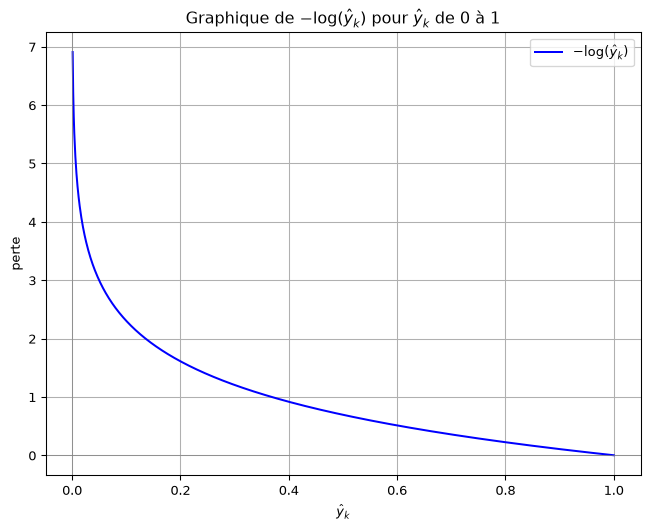

- Dans la somme, seul le terme où $y_k = 1$ contribue une valeur non
  nulle.

- En raison du signe négatif précédant la somme, la valeur de la
  fonction est $-\log(\hat{y}_k)$.

- Si la probabilité prédite $\hat{y}_k$ est proche de 1, la perte
  approche de zéro, indiquant une pénalité minimale.

- À l’inverse, lorsque $\hat{y}_k$ approche de 0, indiquant une mauvaise
  prédiction, la perte approche l’infini. Cette pénalité importante
  permet à la perte d’entropie croisée de converger plus rapidement que
  l’erreur quadratique moyenne.

## Cas : ensemble de données

Pour un ensemble de données avec $N$ exemples, la **perte moyenne
d’entropie croisée** sur tous les exemples est calculée comme suit :

$$
L = -\frac{1}{N} \sum_{i=1}^{N} \sum_{k=1}^{K} y_{i,k} \log(\hat{y}_{i,k})
$$

Où :

- $i$ est l’index des **exemples** dans l’ensemble de données.
- $y_{i,k}$ et $\hat{y}_{i,k}$ sont respectivement les **valeurs
  réelles** et les **probabilités prédites** pour la classe $k$ de
  l’exemple $i$.

# Régularisation

## Définition

La **régularisation** regroupe un ensemble de techniques visant à
améliorer la capacité de généralisation d’un modèle en **atténuant le
surapprentissage**. En **décourageant une complexité excessive du
modèle**, ces méthodes **améliorent** la **robustesse** et la
**performance** du modèle sur des données non vues.

## Ajout de termes de pénalité à la perte

- En optimisation numérique, il est courant d’**ajouter des termes
  supplémentaires** à la **fonction objectif** afin de **dissuader
  certaines caractéristiques indésirables du modèle**.

- Pour un **problème de minimisation**, le processus d’optimisation vise
  à **éviter des coûts élevés** associés à ces **termes de pénalité**.

## Fonction de perte

Prenons la fonction de perte de l’**erreur absolue moyenne** :

$$
  \mathrm{MAE}(X,W) = \frac{1}{N} \sum_{i=1}^{N} | h_W(x_i) - y_i |
$$

Où :

- $W$ sont les poids de notre réseau.
- $h_W(x_i)$ est la sortie du réseau pour l’exemple $i$.
- $y_i$ est la vraie étiquette pour l’exemple $i$.

## Terme(s) de pénalité

Un ou plusieurs termes peuvent être ajoutés à la perte :

$$
  \mathrm{MAE}(X,W) = \frac{1}{N} \sum_{i=1}^{N} | h_W(x_i) - y_i | + \mathrm{pénalité}
$$

## Norme

Une **norme** assigne une longueur non négative à un vecteur.

La **norme $\ell_p$** d’un vecteur
$\mathbf{z} = [z_1, z_2, \ldots, z_n]$ est définie comme suit :

$$
  \|\mathbf{z}\|_p = \left( \sum_{i=1}^{n} |z_i|^p \right)^{1/p}
$$

Avec des valeurs de $p$ plus grandes, la norme $\ell_p$ met de plus en
plus l’accent sur les valeurs de $z_i$ les plus grandes à cause de
l’exponentiation.

Une **norme** est une fonction qui attribue une longueur ou taille non
négative à chaque vecteur dans un espace vectoriel, en respectant
certaines propriétés : positivité, multiplication scalaire, inégalité
triangulaire, et le fait que la norme est nulle si et seulement si le
vecteur est nul.

## Normes $\ell_1$ et $\ell_2$

La **norme $\ell_1$** (**norme de Manhattan**) est :

$$
  \|\mathbf{z}\|_1 = \sum_{i=1}^{n} |z_i|
$$

La **norme $\ell_2$** (**norme euclidienne**) est :

$$
  \|\mathbf{z}\|_2 = \sqrt{\sum_{i=1}^{n} z_i^2}
$$

## Régularisation $l_1$ et $l_2$

Ci-dessous, $\alpha$ et $\beta$ déterminent le degré de régularisation
appliqué ; fixer ces valeurs à zéro désactive effectivement le terme de
régularisation.

$$
  \mathrm{MAE}(X,W) = \frac{1}{N} \sum_{i=1}^{N} | h_W(x_i) - y_i | + \alpha \ell_1 + \beta \ell_2
$$

## Recommandations

- **Régularisation $\ell_1$** :
  - Encourage la **parcimonie**, mettant à zéro beaucoup de poids.
  - Utile pour la **sélection d’attributs** en réduisant la dépendance à
    certains attributs.
- **Régularisation $\ell_2$** :
  - Encourage des **poids petits et répartis** pour la stabilité.
  - Idéal lorsque **toutes les attributs contribuent** et que la
    réduction de la complexité est primordiale.

Voir [kong_and_yu-2018](kong_and_yu-2018) pour un exemple.

## Exemple Keras

In [7]:
import tensorflow as tf
from tensorflow.python.keras.layers import Dense

regularizer = tf.keras.regularizers.l2(0.001)

dense = Dense(50, kernel_regularizer=regularizer)

Cette couche utilise spécifiquement la régularisation $\ell_2$,
contrairement à la discussion précédente où la régularisation était
appliquée globalement à l’ensemble du modèle.

## Dropout

Le **dropout** est une technique de régularisation dans les réseaux
neuronaux où *des neurones sélectionnés aléatoirement sont ignorés
pendant l’entraînement*, réduisant ainsi le surapprentissage en
**empêchant la co-adaptation des attributs**.

Hinton et al. (2012)

## Dropout

- Lors de chaque étape d’entraînement, chaque neurone dans une couche de
  dropout a une probabilité $p$ d’être **exclu du calcul**, des valeurs
  typiques de $p$ allant de 10 % à 50 %.

- Bien que cela puisse sembler contre-intuitif, cette approche **empêche
  le réseau de dépendre de neurones spécifiques**, favorisant ainsi la
  **distribution des représentations apprises sur plusieurs neurones**.

## Dropout

- Le dropout est l’une des méthodes de régularisation **les plus
  populaires** et **les plus efficaces** pour réduire le
  surapprentissage.

- L’amélioration typique des performances est **modeste**, généralement
  autour de 1 à 2 %.

Pendant l’entraînement, chaque neurone dans une couche de dropout est
aléatoirement exclu (mis à zéro) avec une probabilité $p$ — le taux de
dropout.

Lorsque le dropout « met un neurone à zéro », cela signifie que pour
l’étape d’entraînement en cours (mini-lot), l’activation de sortie de ce
neurone est remplacée par zéro. Le neurone existe toujours dans le
réseau, ses poids ne sont ni supprimés ni modifiés, mais sa sortie ne
contribue en rien au passage avant ou arrière pour ce lot.

Dans le lot suivant, un nouveau masque aléatoire est échantillonné, donc
un sous-ensemble différent de neurones est exclu. Au fil de nombreuses
itérations, tous les neurones participent, mais jamais tous en même
temps.

Lors de l’inférence, le mécanisme est désactivé, tous les neurones sont
actifs.

## Keras

In [8]:
import keras
from keras.models import Sequential
from keras.layers import InputLayer, Dropout, Flatten, Dense

model = tf.keras.Sequential([
    InputLayer(shape=[28, 28]),
    Flatten(),
    Dropout(rate=0.2),
    Dense(300, activation="relu"),
    Dropout(rate=0.2),
    Dense(100, activation="relu"),
    Dropout(rate=0.2),
    Dense(10, activation="softmax")
])

Ajout de couches `Dropout` au modèle Fashion-MNIST de la dernière leçon.

Le taux de dropout peut différer entre les couches ; des taux plus
élevés peuvent être appliqués aux couches plus larges, tandis que des
taux plus petits sont adaptés aux couches plus petites. Il est courant
dans de nombreux réseaux d’appliquer le dropout uniquement après la
dernière couche cachée.

## Définition

L’**arrêt anticipé** (*early stopping*) est une technique de
régularisation qui interrompt l’entraînement dès que la performance du
modèle sur un ensemble de validation commence à se dégrader, empêchant
ainsi le surapprentissage en s’arrêtant avant que le modèle n’apprenne
le bruit.

Geoffrey Hinton appelle cela le *“beau repas gratuit.”*

## Early Stopping

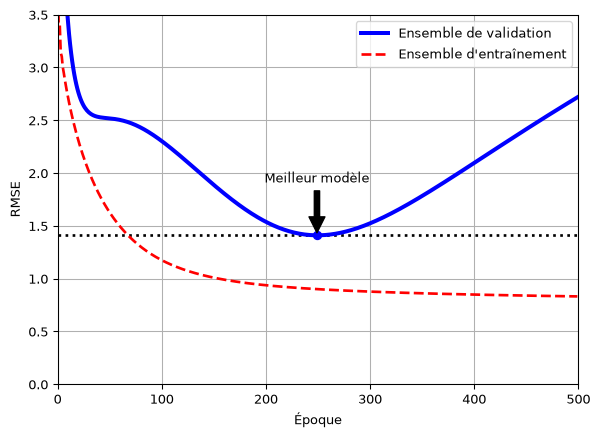

**Attribution** : Géron (2022),
[04_training_linear_models.ipynb](https://github.com/ageron/handson-ml3/blob/main/04_training_linear_models.ipynb).

# Prologue

## Résumé

- **Propagation des gradients** : Les dérivées des activations et
  l’initialisation influencent l’entraînement. ReLU et une mise à
  l’échelle appropriée atténuent certaines limites des réseaux
  sigmoïdes.

- **Implémentation** : `SimpleMLP` conserve la structure de `SimplerMLP`
  et ajoute un choix d’activations cachées, une régularisation L2
  optionnelle et la décroissance du taux d’apprentissage.

- **Fonctions de perte** :

  - **Tâches de régression** : Erreur quadratique moyenne (MSE).
  - **Tâches de classification** : Perte d’entropie croisée avec
    activation softmax pour les sorties multiclasses.

- **Techniques de régularisation** :

  - **Régularisation L1 et L2** : Ajouter des termes de pénalité à la
    perte pour décourager les poids élevés.
  - **Dropout** : Désactiver aléatoirement des neurones pendant
    l’entraînement pour éviter le surapprentissage.
  - **Early Stopping** : Interrompre l’entraînement lorsque la
    performance de validation se dégrade.

## Prochain cours

- Nous introduirons les réseaux convolutifs.

## Références

Géron, Aurélien. 2022. *Hands-on Machine Learning with Scikit-Learn,
Keras, and TensorFlow*. 3ᵉ éd. O’Reilly Media, Inc.

Glorot, Xavier, et Yoshua Bengio. 2010. « Understanding the difficulty
of training deep feedforward neural networks ». In *Proceedings of the
Thirteenth International Conference on Artificial Intelligence and
Statistics*, édité par Yee Whye Teh et Mike Titterington, vol. 9.
Proceedings of Machine Learning Research. PMLR.
<https://proceedings.mlr.press/v9/glorot10a.html>.

Hinton, Geoffrey E., Nitish Srivastava, Alex Krizhevsky, Ilya Sutskever,
et Ruslan Salakhutdinov. 2012. « Improving neural networks by preventing
co-adaptation of feature detectors ». *CoRR* abs/1207.0580.
<http://arxiv.org/abs/1207.0580>.

Russell, Stuart, et Peter Norvig. 2020. *Artificial Intelligence: A
Modern Approach*. 4ᵉ éd. Pearson. <http://aima.cs.berkeley.edu/>.

------------------------------------------------------------------------

Marcel **Turcotte**

<Marcel.Turcotte@uOttawa.ca>

École de **science informatique** et de génie électrique (**SI**GE)

Université d’Ottawa